# 05 — The controlled ML model

**What this shows:** how the SDK simulates a predictive model with a chosen performance, and how to check it.

`ControlledMLModel` (`healthcare_sim_sdk/ml/model.py`) produces scores from each patient's **true risk plus noise**. It never sees the outcome it predicts (*label-free*). The noise level is tuned on a reference population until the scores reach the target AUC.

Four facts to take from this notebook:

1. No model can beat the population's **Bayes ceiling**: the AUC of an oracle that knows every true risk.
2. The model is fitted on a large **reference cohort** (`fit_reference`), not on the few events of one simulation step.
3. A fit report is not evidence. Check AUC on a population the model was not fitted to (`auc_fidelity`).
4. An unreachable target fails loudly (`OperatingPointError`) instead of silently delivering something else.

This notebook replaces the earlier `ControlledBinaryClassifier`, which added a boost to patients who would have the event and could therefore beat the Bayes ceiling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from healthcare_sim_sdk.core.rng import RNGPartitioner
from healthcare_sim_sdk.ml.fidelity import auc_fidelity
from healthcare_sim_sdk.ml.model import ControlledMLModel, OperatingPointError
from healthcare_sim_sdk.ml.performance import auc_exact, confusion_matrix_metrics, roc_curve
from healthcare_sim_sdk.population.risk_distributions import beta_distributed_risks

streams = RNGPartitioner(42).create_streams()

## 1. A population and its Bayes ceiling

20,000 patients with Beta-distributed risk: mean 10%, concentration 0.5. Outcomes are drawn from those risks.

In [2]:
n = 20_000
risks = beta_distributed_risks(n_patients=n, annual_incident_rate=0.10,
                               concentration=0.5, rng=streams.population)
labels = (streams.outcomes.random(n) < risks).astype(int)
ceiling = auc_exact(labels, risks)
print(f"event rate          {labels.mean():.3f}")
print(f"Bayes ceiling (AUC) {ceiling:.3f}  <- the oracle that knows every true risk")

event rate          0.096
Bayes ceiling (AUC) 0.831  <- the oracle that knows every true risk


## 2. Fit to a target AUC on a reference cohort

`fit_reference` draws a bootstrap cohort from the population's risk distribution, with at least `min_events` events, and tunes the noise there. The simulation's own outcomes are not used.

In [3]:
model = ControlledMLModel(mode="discrimination", target_auc=0.75)
report = model.fit_reference(risks, streams.prediction, min_events=1000)
print(f"reference cohort    {report['reference_cohort_size']:,} patients")
print(f"fit-report AUC      {report['achieved_auc']:.3f} (target 0.75)")

reference cohort    10,000 patients
fit-report AUC      0.741 (target 0.75)


## 3. Check on data the model was not fitted to

A fresh population from the same distribution, with its own outcomes. The model is frozen; only `predict` is called. `auc_fidelity` computes the exact AUC and says PASS, FAIL, or INCONCLUSIVE when one class is too small.

In [4]:
fresh_streams = RNGPartitioner(7).create_streams()
risks_new = beta_distributed_risks(n_patients=n, annual_incident_rate=0.10,
                                   concentration=0.5, rng=fresh_streams.population)
labels_new = (fresh_streams.outcomes.random(n) < risks_new).astype(int)
scores_new = model.predict(risks_new, fresh_streams.prediction)

check = auc_fidelity(labels_new, scores_new, target_auc=0.75, tolerance=0.02,
                     independent_cohort=True, scope="fresh synthetic population")
print(f"held-out AUC        {check['achieved_auc']:.3f}  -> {check['status']}")
print(f"oracle on same data {auc_exact(labels_new, risks_new):.3f}  (the model stays below it)")

held-out AUC        0.747  -> PASS
oracle on same data 0.835  (the model stays below it)


## 4. Label-free: the outcome does not change the scores

`predict` still accepts outcome labels for backward compatibility, and ignores them. Scoring the same patients from the same random state, once without and once with their outcomes, gives identical scores. A model cannot borrow information it would not have in practice.

In [5]:
a = model.predict(risks_new, RNGPartitioner(99).create_streams().prediction)
b = model.predict(risks_new, RNGPartitioner(99).create_streams().prediction,
                  true_labels=labels_new)
print("identical with and without outcomes:", bool(np.array_equal(a, b)))

identical with and without outcomes: True


## 5. An operating point: hold PPV, get the sensitivity the AUC allows

At a fixed prevalence, PPV and sensitivity cannot both be chosen freely; the AUC determines the trade-off. `operating_point` mode holds one of them (`binding`) and takes either an AUC or a goal for the other.

In [6]:
op = ControlledMLModel(mode="operating_point", target_auc=0.75,
                       binding="ppv", binding_value=0.25)
op_report = op.fit_reference(risks, streams.prediction, min_events=1000)
op_scores = op.predict(risks_new, fresh_streams.prediction)
m = confusion_matrix_metrics(labels_new, op_scores, op_report["threshold"])
print(f"held-out PPV {m['ppv']:.3f} (held at 0.25), sensitivity {m['sensitivity']:.3f}, "
      f"flagged {m['flag_rate']:.1%}")

held-out PPV 0.256 (held at 0.25), sensitivity 0.557, flagged 22.1%


## 6. Unreachable targets fail loudly

Sensitivity 0.80 at PPV 0.50 needs an AUC above this population's ceiling. The model refuses rather than delivering a different model under the same name. `allow_infeasible=True` fits anyway and records the gap.

In [7]:
try:
    ControlledMLModel(mode="operating_point", binding="ppv", binding_value=0.50,
                      goal_value=0.80).fit_reference(risks, streams.prediction)
except OperatingPointError as error:
    print(str(error).splitlines()[0])

Mode 'operating_point' requires AUC 0.9396, which exceeds this population's Bayes ceiling of 0.8357 (standard error 0.0057).


## 7. ROC curves: model, oracle and chance

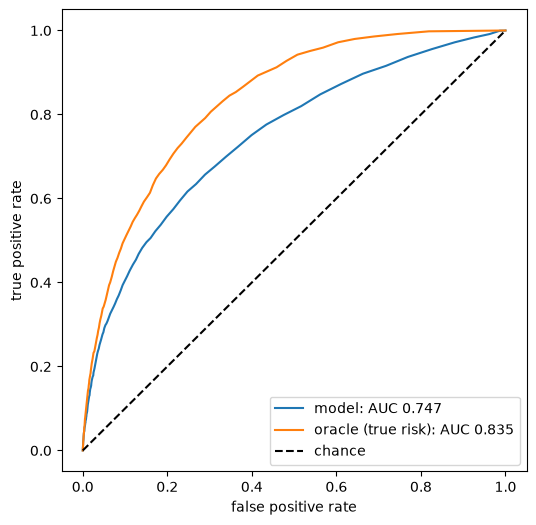

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, s in (("model", scores_new), ("oracle (true risk)", risks_new)):
    fpr, tpr, _ = roc_curve(labels_new, s)
    ax.plot(fpr, tpr, label=f"{name}: AUC {auc_exact(labels_new, s):.3f}")
ax.plot([0, 1], [0, 1], "k--", label="chance")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.legend(loc="lower right"); plt.show()

## Key points

1. The Bayes ceiling bounds every model on a population. Check a target against it before simulating.
2. Fit on a reference cohort with enough events; a few dozen events give an unreliable fit.
3. Judge the model on held-out data with `auc_fidelity`, never on its own fit report.
4. Scores come from true risk and noise only. A simulated model that sees outcomes overstates what any deployed model could do.